In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path
import sys, os
from datetime import datetime, timedelta

import warnings
warnings.filterwarnings("ignore")

sys.path.append("/home/548/cd3022/repos/nowcast-evaluation/src")
import nowcast_preprocess

In [3]:
YEAR = "2025"
MONTH = "01"
DAY = "02"
lat_min, lat_max, lon_min, lon_max = -35, -25, 140, 150
def preprocess_truth(ds):
    return ds.sel(
        latitude=slice(lat_min, lat_max),
        longitude=slice(lon_min, lon_max)
    )[["surface_global_irradiance"]]

In [6]:
truth_path = Path(f"/g/data/rv74/satellite-products/arc/der/himawari-ahi/solar/p1s/latest/{YEAR}/{MONTH}/{DAY}")
truth_files = sorted([f for f in truth_path.rglob("*.nc")])
truth = xr.open_mfdataset(
    truth_files,
    preprocess = preprocess_truth,
    concat_dim='time',
    combine='nested',
    data_vars='minimal',
    coords='minimal',
    compat='override',
    parallel=True,
    chunks='auto'
)

In [8]:
CLEAR_SKY_DIR = Path(
    "/g/data/ob53/BARRA2/output/reanalysis/AUST-04/BOM/ERA5/historical/hres/BARRA-C2/v1/1hr/rsdscs/latest"
)

cs_files = sorted([f for f in CLEAR_SKY_DIR.glob(f"*_{YEAR}*.nc")])
clear_sky = xr.open_mfdataset(cs_files)

In [10]:
clear_sky, _ = xr.align(clear_sky, truth, join="inner")

In [12]:
clear_sky = clear_sky.interp(
    time=truth.time,
    method="linear"
)
clear_sky = clear_sky.interp(
    lat=truth.latitude,
    lon=truth.longitude
)

In [15]:
csi = truth.surface_global_irradiance / clear_sky.rsdscs

In [23]:
"""
Classify clear-sky-index (CSI) imagery into cloud regimes by cloud size.

Classes (per block of `block` x `block` pixels):
    0 = clear sky       -> little cloud in the block
    1 = patchy clouds   -> cloud present, mostly belonging to small objects
    2 = fully clouded   -> cloud present, mostly belonging to large objects
                           (or the block is almost entirely cloud-covered)

Method, per time step:
  1. Cloud mask: CSI < csi_cloud_thresh.
  2. Label connected cloud objects (8-connectivity) across the full scene,
     so a cloud's size is measured over its whole extent, not just inside one block.
  3. Give each cloudy pixel the area (in pixels) of the cloud it belongs to.
  4. For each block, compute
        cloud_frac  = fraction of valid pixels that are cloudy
        large_frac  = fraction of cloudy pixels that belong to "large" clouds
     and classify:
        cloud_frac <  clear_frac                         -> clear
        cloud_frac >= overcast_frac or large_frac >= 0.5 -> fully clouded
        otherwise                                        -> patchy

All thresholds are arguments - tune them to your sensor resolution and region.
"""

import numpy as np
import xarray as xr
from scipy import ndimage

CLASS_NAMES = {0: "clear", 1: "patchy", 2: "fully_clouded"}

_EIGHT_CONNECTED = np.ones((3, 3), dtype=bool)


def _cloud_object_size(csi_2d, csi_cloud_thresh):
    """Return (cloud_mask, size_map) for one 2D image.

    size_map holds, for each cloudy pixel, the pixel area of its connected
    cloud object; 0 for clear pixels. NaNs are treated as not-cloud.
    """
    cloud = np.nan_to_num(csi_2d, nan=np.inf) < csi_cloud_thresh
    labels, n = ndimage.label(cloud, structure=_EIGHT_CONNECTED)
    sizes = np.bincount(labels.ravel())
    sizes[0] = 0  # background
    return cloud, sizes[labels]


def _classify_2d(csi_2d, block, csi_cloud_thresh, large_cloud_px,
                 clear_frac, overcast_frac, min_valid_frac):
    """Classify one 2D image into a (ny//block, nx//block) array of classes.

    Returns float arrays (class, cloud_frac, large_frac); class is NaN where
    a block has too few valid pixels.
    """
    ny, nx = csi_2d.shape
    by, bx = ny // block, nx // block
    csi_2d = csi_2d[: by * block, : bx * block]  # trim ragged edge

    valid = np.isfinite(csi_2d)
    cloud, size_map = _cloud_object_size(csi_2d, csi_cloud_thresh)
    large = cloud & (size_map >= large_cloud_px)

    def block_sum(a):
        return a.reshape(by, block, bx, block).sum(axis=(1, 3)).astype(float)

    n_valid = block_sum(valid)
    n_cloud = block_sum(cloud)
    n_large = block_sum(large)

    with np.errstate(invalid="ignore", divide="ignore"):
        cloud_frac = n_cloud / n_valid
        large_frac = np.where(n_cloud > 0, n_large / n_cloud, 0.0)

    cls = np.full((by, bx), 1.0)  # default patchy
    cls[cloud_frac < clear_frac] = 0.0
    full = (cloud_frac >= clear_frac) & (
        (cloud_frac >= overcast_frac) | (large_frac >= 0.5)
    )
    cls[full] = 2.0

    bad = n_valid < min_valid_frac * block * block
    cls[bad] = np.nan
    cloud_frac[bad] = np.nan
    large_frac[bad] = np.nan
    return cls, cloud_frac, large_frac


def classify_cloud_regimes(
    da,
    block=5,
    csi_cloud_thresh=0.7,
    large_cloud_px=100,
    clear_frac=0.2,
    overcast_frac=0.9,
    min_valid_frac=0.5,
    lat="latitude",
    lon="longitude",
):
    """Classify a (time, lat, lon) clear-sky-index DataArray into cloud regimes.

    Parameters
    ----------
    da : xr.DataArray
        Clear-sky index, dims include `lat` and `lon` (and usually `time`).
    block : int
        Block size in pixels (block x block) for the classification.
    csi_cloud_thresh : float
        Pixels with CSI below this are cloudy. 0.6-0.8 is typical.
    large_cloud_px : int
        A connected cloud with at least this many pixels counts as "large".
        100 px ~ a 10x10 pixel cloud, i.e. clearly bigger than one 5x5 block.
    clear_frac : float
        Blocks with cloud fraction below this are "clear".
    overcast_frac : float
        Blocks with cloud fraction at/above this are "fully clouded"
        regardless of object size.
    min_valid_frac : float
        Blocks with fewer valid (non-NaN) pixels than this fraction are NaN.

    Returns
    -------
    xr.Dataset with variables at block resolution:
        regime      : 0 clear, 1 patchy, 2 fully clouded (NaN = insufficient data)
        cloud_frac  : cloud fraction in the block
        large_frac  : fraction of the block's cloud belonging to large clouds
    """
    kwargs = dict(
        block=block,
        csi_cloud_thresh=csi_cloud_thresh,
        large_cloud_px=large_cloud_px,
        clear_frac=clear_frac,
        overcast_frac=overcast_frac,
        min_valid_frac=min_valid_frac,
    )

    def _wrapped(arr):
        # arr has core dims (lat, lon) last; loop over any leading dims (e.g. time)
        lead = arr.shape[:-2]
        flat = arr.reshape((-1,) + arr.shape[-2:])
        outs = [_classify_2d(a, **kwargs) for a in flat]
        stacked = [np.stack([o[i] for o in outs]) for i in range(3)]
        return tuple(s.reshape(lead + s.shape[-2:]) for s in stacked)

    ny, nx = da.sizes[lat], da.sizes[lon]
    by, bx = ny // block, nx // block

    regime, cloud_frac, large_frac = xr.apply_ufunc(
        _wrapped,
        da,
        input_core_dims=[[lat, lon]],
        output_core_dims=[["blat", "blon"]] * 3,
        dask="parallelized",
        dask_gufunc_kwargs={"output_sizes": {"blat": by, "blon": bx},
                            "allow_rechunk": True},
        output_dtypes=[float] * 3,
    )

    # Block-centre coordinates
    blat = da[lat].values[: by * block].reshape(by, block).mean(axis=1)
    blon = da[lon].values[: bx * block].reshape(bx, block).mean(axis=1)

    ds = xr.Dataset(
        {"regime": regime, "cloud_frac": cloud_frac, "large_frac": large_frac}
    ).rename({"blat": lat, "blon": lon}).assign_coords({lat: blat, lon: blon})

    ds["regime"].attrs = {
        "long_name": "cloud regime",
        "flag_values": [0, 1, 2],
        "flag_meanings": "clear patchy fully_clouded",
    }
    ds.attrs.update({f"param_{k}": v for k, v in kwargs.items()})
    return ds


def regime_to_full_res(regime, like, lat="lat", lon="lon"):
    """Map block-resolution regimes back onto the original pixel grid."""
    return regime.reindex(
        {lat: like[lat], lon: like[lon]}, method="nearest"
    )


if __name__ == "__main__":
    # Example usage:
    # ds = xr.open_dataset("your_file.nc")
    # csi = ds["csi"]                      # (time, lat, lon), values ~0-1
    # out = classify_cloud_regimes(csi, block=5)
    # out["regime"].isel(time=0).plot(levels=[-0.5, 0.5, 1.5, 2.5])
    # out.to_netcdf("cloud_regimes.nc")
    pass

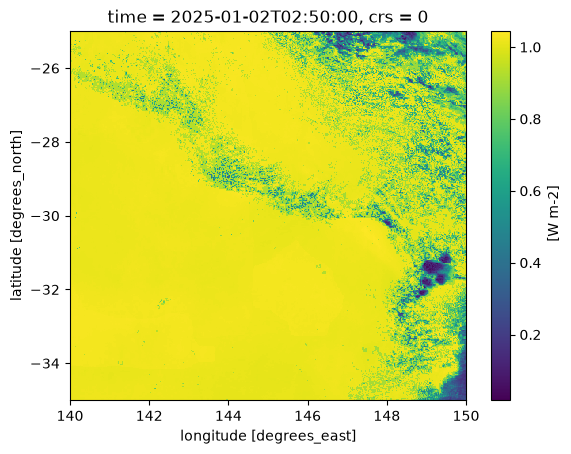

In [28]:
csi.isel(time=50).plot()

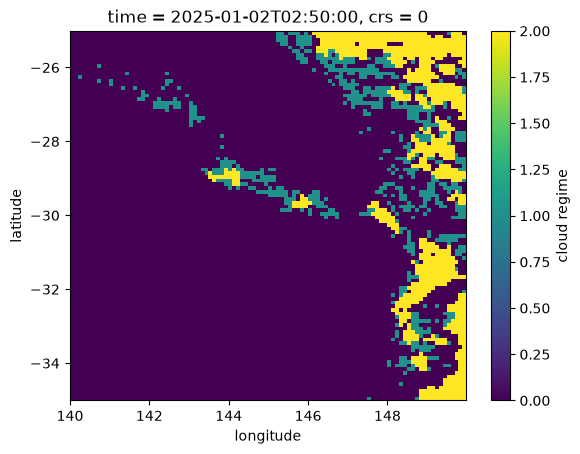

In [29]:
classify_cloud_regimes(csi, block=5, csi_cloud_thresh=0.8).isel(time=50).regime.plot()